In [16]:
import os
os.environ["KERAS_BACKEND"] = "torch"   # must be set BEFORE importing keras

from pathlib import Path
import time

import h5py                              # reads the .h5 file
import numpy as np                       # numerical arrays
import pandas as pd                      # tables
import matplotlib.pyplot as plt          # plots
import torch                             # compute engine used by Keras
import keras
from keras import layers                 # network building blocks (Conv1D, Dense, ...)
from sklearn.decomposition import PCA
from numpy.lib.stride_tricks import sliding_window_view   # cuts the windows
from IPython.display import display

get_ipython().run_line_magic("matplotlib", "inline")      # plots appear below the cell

path = Path("data") / "/lustre/orange2/markaf.fiu/srija/CGN_5878/data_100Hz.h5"   # put the dataset in the data folder next to this notebook

# --- settings ---
TARGET = "SB05_x"                         # strain channel to predict
N_PC = 25                                 # number of principal components to keep
fs = 100                                  # sampling frequency [Hz]
SEED = 0                                  # fixed random seed: same results at every run

LONG_WIN = 500                           # window length in samples (500 samples = 5 s)
OVERLAP = 0.50                            # overlap between consecutive windows (50 %)
STRIDE = max(1, int(round(LONG_WIN * (1 - OVERLAP))))     # shift between window starts, in samples (500)

SPLIT = (0.70, 0.15, 0.15)                # fractions of each recording, in time order: train, validation, test
assert abs(sum(SPLIT) - 1) < 1e-9, "SPLIT fractions must add up to 1"

assert Path(path).is_file(), "File not found: check the path"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"   # NVIDIA GPU if available, otherwise CPU
print("Keras", keras.__version__, "| backend:", keras.backend.backend(),
      "| PyTorch", torch.__version__, "| device:", DEVICE)

ADD_NOISE_TO_TRAINING = False              # True: the undamaged noise-mode recordings are added to the training set; False: sweeps only
SCALE_TARGET = True 

Keras 3.12.4 | backend: torch | PyTorch 2.8.0+cu128 | device: cuda


## 2 Recordings

The recordings used are the **undamaged (UDS) sweep (SM) recordings**: 2 shaker positions (P1, P2), 2 directions (Y, Z) and 2 repetitions, 8 recordings in total. The noise-mode recordings (NM) are excluded.

In [17]:
with h5py.File(path, "r") as f:
    all_names = list(f.keys())

rows = []
for n in all_names:
    _, position, state, mode, direction, rep = n.split("_")
    rows.append({"name": n, "position": position, "state": state,
                 "mode": mode, "direction": direction, "rep": rep})
meta_all = pd.DataFrame(rows)

is_uds = meta_all["state"] == "UDS"
sweep_names = list(meta_all[is_uds & (meta_all["mode"] == "SM")]["name"])
noise_names = list(meta_all[is_uds & (meta_all["mode"] == "NM")]["name"]) if ADD_NOISE_TO_TRAINING else []

# Balanced 7 / 2 / 1 Recording-Level Split:
# - Test (1): 1 unseen sweep recording (P2_Y_02)
# - Val  (2): 1 unseen sweep recording (P1_Z_02) + 1 unseen noise recording (last NM)
# - Train(7): 6 sweep recordings covering ALL 4 (position, direction) pairs + 1 noise recording
test_names = ["MVS_P2_UDS_SM_Y_02"]
val_names = ["MVS_P1_UDS_SM_Z_02"] + ([noise_names[-1]] if noise_names else [])
train_names = [n for n in sweep_names if n not in val_names + test_names] + ([noise_names[0]] if noise_names else [])
used_names = train_names + val_names + test_names

print(f"Train ({len(train_names)} recs):", train_names)
print(f"Val   ({len(val_names)} recs):", val_names)
print(f"Test  ({len(test_names)} recs):", test_names)


Train (6 recs): ['MVS_P1_UDS_SM_Y_01', 'MVS_P1_UDS_SM_Y_02', 'MVS_P1_UDS_SM_Z_01', 'MVS_P2_UDS_SM_Y_01', 'MVS_P2_UDS_SM_Z_01', 'MVS_P2_UDS_SM_Z_02']
Val   (1 recs): ['MVS_P1_UDS_SM_Z_02']
Test  (1 recs): ['MVS_P2_UDS_SM_Y_02']


In [18]:
def is_wanted(ch):
    return ch.startswith("AL") or (ch.startswith("AG") and ch.endswith(("_y", "_z"))) or ch == TARGET   # 75 accelerations + target

def load_recording(name):
    cols = {}
    with h5py.File(path, "r") as f:
        for group in ("acceleration", "strain"):
            for sensor in f[name][group]:
                for axis in f[name][group][sensor]:
                    ch = f"{sensor}_{axis}"                                           # channel name, e.g. AG01_y
                    if is_wanted(ch):                                                 # load only the channels we need
                        cols[ch] = f[name][group][sensor][axis][:].astype("float32")  # read all values, float32 to save memory
        unit = f[name]["strain"][TARGET.split("_")[0]].attrs["unit"]                  # unit of the target
    d = pd.DataFrame(cols)                                                            # one column per channel
    d.index = np.arange(len(d)) / fs                                                  # time in seconds
    d.index.name = "Time [s]"
    return d, unit

recordings, units = {}, set()   #dafinizione del dataset
for n in used_names:                                                                  # sweep recordings first, then the noise ones
    d, u = load_recording(n)
    recordings[n] = d                                                                 # table of this recording
    units.add(u)

acc_cols = sorted(c for c in recordings[used_names[0]].columns if c != TARGET)         # the 75 acceleration channels, in alphabetical order
assert len(acc_cols) == 75, len(acc_cols)
for n in used_names:
    assert set(recordings[n].columns) == set(acc_cols) | {TARGET}, n                  # check: same channels in every recording
    recordings[n] = recordings[n][acc_cols + [TARGET]]                                # same column order everywhere
assert len(units) == 1                                                                # check: same unit in every recording
target_unit = units.pop()

for n, d in recordings.items():
    print(f"{n}: {len(d)} samples ({len(d) / fs:.0f} s)")
print("Target unit:", target_unit)
display(recordings[used_names[0]].head())

MVS_P1_UDS_SM_Y_01: 62147 samples (621 s)
MVS_P1_UDS_SM_Y_02: 61681 samples (617 s)
MVS_P1_UDS_SM_Z_01: 62410 samples (624 s)
MVS_P2_UDS_SM_Y_01: 62386 samples (624 s)
MVS_P2_UDS_SM_Z_01: 62335 samples (623 s)
MVS_P2_UDS_SM_Z_02: 62382 samples (624 s)
MVS_P1_UDS_SM_Z_02: 62531 samples (625 s)
MVS_P2_UDS_SM_Y_02: 62520 samples (625 s)
Target unit: MPa


,AG01_y,AG01_z,AG02_y,AG02_z,AG03_y,AG03_z,AG04_y,AG04_z,AG05_y,AG05_z,...,AL32_z,AL33_z,AL34_z,AL35_z,AL36_z,AL37_z,AL38_z,AL39_z,AL40_z,SB05_x
Time [s],,,,,,,,,,,,,,,,,,,,,
0.00,0.000058,0.001092,-0.011348,0.008771,0.000409,0.000413,0.005028,0.003098,-0.000492,0.002269,...,0.009926,0.000973,-0.001352,0.000936,-0.000134,0.000465,0.000693,0.000564,0.000754,-0.596685
0.01,-0.000032,0.000821,-0.012555,0.008673,0.000168,-0.000498,0.005462,0.002743,-0.001115,0.001427,...,0.009305,0.001137,-0.000475,0.001530,-0.000516,0.000505,0.000588,0.000314,0.000867,0.570001
0.02,0.000777,0.000395,-0.013792,0.008423,0.000177,-0.000644,0.005892,0.002216,-0.000786,0.000745,...,0.008656,0.000647,-0.000247,0.000791,-0.000762,0.000456,0.001013,0.001129,0.001352,0.070698
0.03,0.001225,0.000077,-0.014491,0.008877,-0.000285,-0.000844,0.006455,0.002084,-0.000660,0.000369,...,0.008078,-0.000027,-0.000399,0.000673,-0.000927,0.000251,0.001025,0.000447,0.000897,0.252693
0.04,0.001112,0.000016,-0.014792,0.009201,-0.000513,-0.001504,0.007108,0.002263,-0.000784,0.000115,...,0.007338,-0.000446,-0.000980,0.000357,-0.001249,0.000384,0.000642,-0.000073,0.000195,0.266413


In [19]:
from sklearn.preprocessing import StandardScaler

# 1. Fit StandardScaler + PCA ONLY on the training recordings
X_train_raw = np.concatenate([recordings[n][acc_cols].values for n in train_names])

acc_scaler = StandardScaler()
X_train_scaled = acc_scaler.fit_transform(X_train_raw)

pca = PCA(n_components=N_PC, random_state=SEED)
pca.fit(X_train_scaled)
print(f"Explained variance on TRAIN with {N_PC} components: {100 * pca.explained_variance_ratio_.sum():.2f} %")

# 2. Transform every recording using the train-fitted scaler and PCA
pc_cols = [f"PC{i + 1}" for i in range(N_PC)]
reduced_full = {}
for n, d in recordings.items():
    x_sc = acc_scaler.transform(d[acc_cols].values)
    r = pd.DataFrame(pca.transform(x_sc), index=d.index, columns=pc_cols).astype("float32")
    r[TARGET] = d[TARGET].values
    reduced_full[n] = r

# 3. Standardize the PCs themselves (fit on train PCs only) so all PCs have unit variance for the CNN/Transformer
pc_scaler = StandardScaler()
pc_scaler.fit(np.concatenate([reduced_full[n][pc_cols].values for n in train_names]))
for n in used_names:
    reduced_full[n][pc_cols] = pc_scaler.transform(reduced_full[n][pc_cols].values).astype("float32")


Explained variance on TRAIN with 25 components: 96.64 %


In [20]:
# 4. Cut sliding windows inside each recording separately (no cross-recording windows)
def make_windows(d, win, stride):
    Z = d[pc_cols].values.astype("float32")
    y = d[TARGET].values.astype("float32")
    X = sliding_window_view(Z, win, axis=0)
    X = np.ascontiguousarray(X.transpose(0, 2, 1)[::stride])
    y_win = y[win - 1:][::stride]
    t_end = d.index.values[win - 1:][::stride]
    return X, y_win, t_end

windows = {}
for n in used_names:
    windows[n] = make_windows(reduced_full[n], LONG_WIN, STRIDE)

def build_split(rec_list):
    X_list, y_list, t_list, id_list = [], [], [], []
    for n in rec_list:
        X, y, t = windows[n]
        rec_id = used_names.index(n)
        X_list.append(X)
        y_list.append(y)
        t_list.append(t)
        id_list.append(np.full(len(X), rec_id))
    return np.concatenate(X_list), np.concatenate(y_list), np.concatenate(t_list), np.concatenate(id_list)

X_train, y_train_phys, t_train, rec_train = build_split(train_names)
X_val, y_val_phys, t_val, rec_val = build_split(val_names)
X_test, y_test_phys, t_test, rec_test = build_split(test_names)

for name, X, y in [("train", X_train, y_train_phys), ("val", X_val, y_val_phys), ("test", X_test, y_test_phys)]:
    print(f"{name:5s} X={X.shape}   y={y.shape}   target mean {y.mean():+.4f}   std {y.std():.4f} {target_unit}")


train X=(1484, 500, 25)   y=(1484,)   target mean -0.0015   std 0.1376 MPa
val   X=(249, 500, 25)   y=(249,)   target mean +0.0011   std 0.0801 MPa
test  X=(249, 500, 25)   y=(249,)   target mean +0.0019   std 0.1115 MPa


## SLIDING WINDOWS


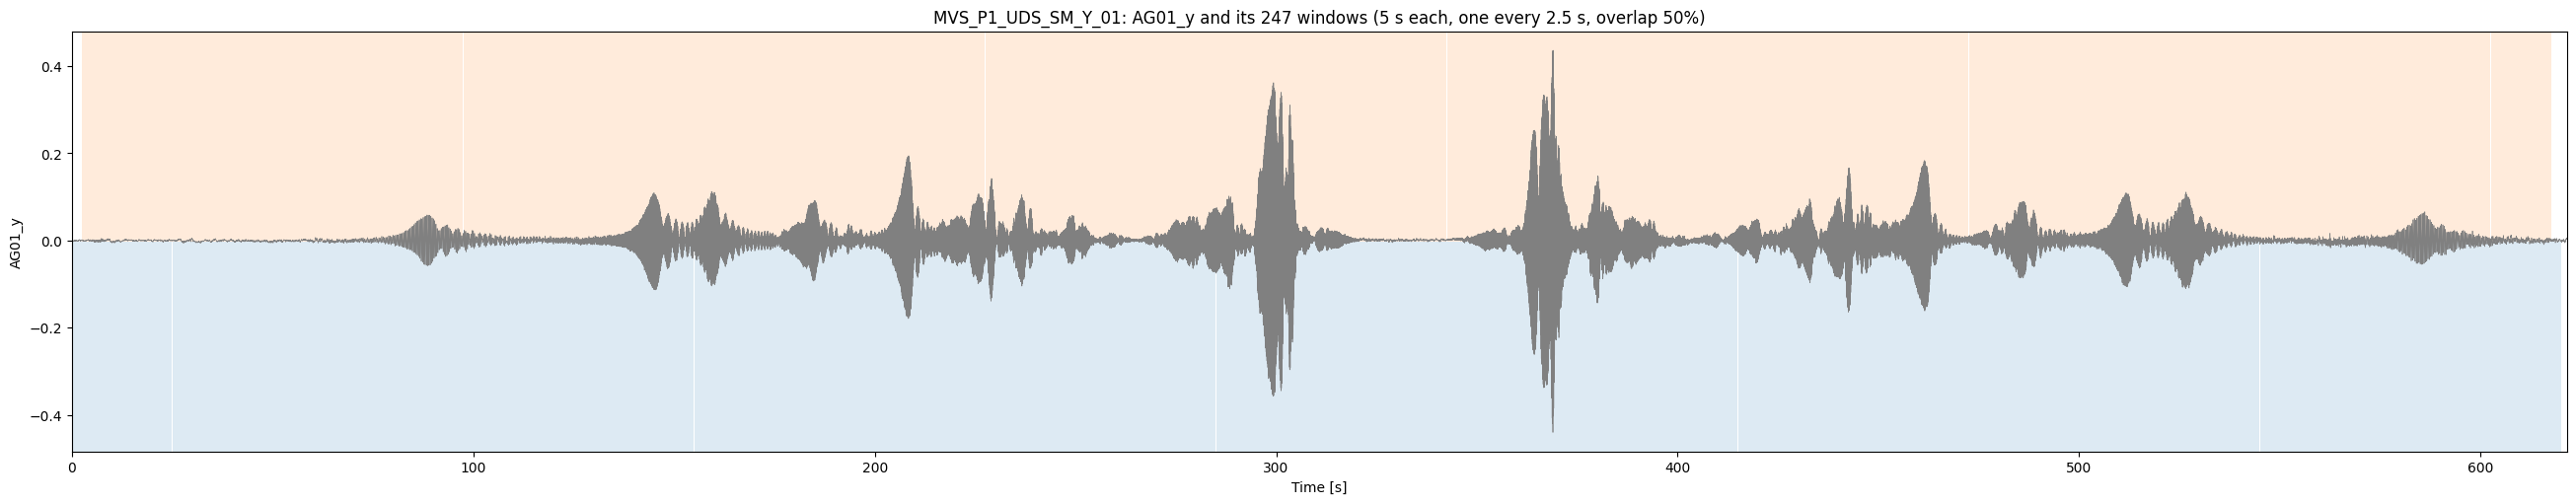

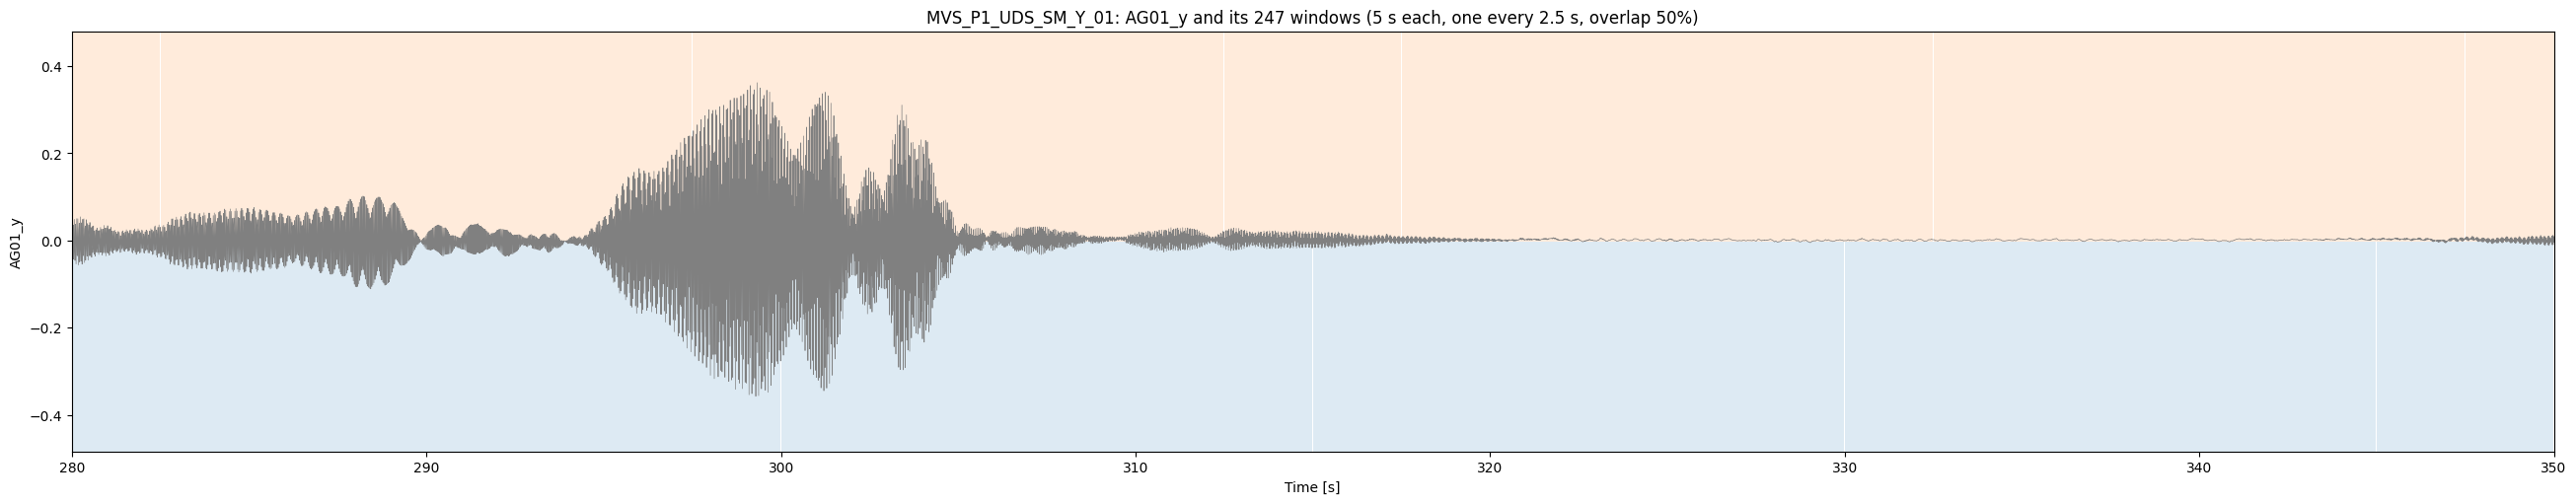

In [21]:
def plot_windows(n, channel=None, t_range=None, fig_size=(26, 5)):
    """An acceleration channel with a translucent rectangle over the part of the recording covered by each window."""
    d = recordings[n]
    channel = channel or acc_cols[0]                          # channel to draw: the first acceleration channel by default
    t_end = windows[n][2]                                     # time of the last sample of each window
    t_start = t_end - (LONG_WIN - 1) / fs                     # time of the first sample of each window
    n_rows = int(np.ceil(LONG_WIN / STRIDE))                  # overlapping windows get different colours and different bands
    t_range = t_range or (d.index[0], d.index[-1])            # time interval to show: the whole recording by default
    visible = [k for k in range(len(t_end)) if t_end[k] >= t_range[0] and t_start[k] <= t_range[1]]

    fig, ax1 = plt.subplots(figsize=fig_size, constrained_layout=True)
    ax1.plot(d.index, d[channel], color="grey", lw=0.5)      # the acceleration channel
    for k in visible:
        c = f"C{k % n_rows % 10}"                             # colour = band of the window: neighbouring windows differ
        row = k % n_rows                                      # band of this window: 0 = lowest band of the plot
        ax1.axvspan(t_start[k], t_end[k], ymin=row / n_rows, ymax=(row + 1) / n_rows,
                    color=c, alpha=0.15, lw=0)                # translucent rectangle, only in its band of the plot height
    ax1.set_xlim(*t_range)
    ax1.set(title=f"{n}: {channel} and its {len(t_end)} windows ({LONG_WIN / fs:g} s each, one every {STRIDE / fs:g} s, overlap {OVERLAP:.0%})",
            xlabel="Time [s]", ylabel=channel)
    plt.show()
    return fig

plot_windows(used_names[0])                                    # the whole first recording
plot_windows(used_names[0], t_range=(280, 350));                # zoom on 40 s, around a burst

In [22]:
TCN_CHANNELS = 32
TCN_KERNEL_SIZE = 5
TCN_DILATIONS = (1, 2, 4, 8, 16, 32, 64)

def build_cnn(n_features=N_PC, lr=5e-4, dropout=0.25): #1e-3
    inputs = layers.Input(shape=(None, n_features))
    features = layers.Conv1D(TCN_CHANNELS, 1, padding="causal", name="input_projection")(inputs)
    for i, dilation in enumerate(TCN_DILATIONS):
        residual = features
        x = layers.Conv1D(TCN_CHANNELS, TCN_KERNEL_SIZE, padding="causal",
                          dilation_rate=dilation, name=f"temporal_convolution_{i}")(features)
        x = layers.LayerNormalization()(x)    #we tried batch normalization first
        x = layers.Activation("relu")(x)
        x = layers.SpatialDropout1D(dropout)(x)
        features = layers.Add()([residual, x])
    last = features[:, -1, :]
    output = layers.Dense(1)(last)
    model = keras.Model(inputs, output, name="causal_temporal_cnn")
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="mse")
    return model



In [23]:

# Cell 8: Target Standardization (Fit on Train Only)

if SCALE_TARGET:
    y_mean_tr = y_train_phys.mean()
    y_std_tr = y_train_phys.std()
else:
    y_mean_tr, y_std_tr = 0.0, 1.0

y_train = ((y_train_phys - y_mean_tr) / y_std_tr).astype("float32")
y_val = ((y_val_phys - y_mean_tr) / y_std_tr).astype("float32")
y_test = ((y_test_phys - y_mean_tr) / y_std_tr).astype("float32")

def to_physical(y_scaled):
    return y_scaled * y_std_tr + y_mean_tr

print(f"SCALE_TARGET = {SCALE_TARGET}")
print(f"y_train:   mean = {y_train.mean():+.5f}   std = {y_train.std():.5f}")
print(f"y_val:     mean = {y_val.mean():+.5f}   std = {y_val.std():.5f}")
print(f"y_test:    mean = {y_test.mean():+.5f}   std = {y_test.std():.5f}")
assert np.allclose(to_physical(y_train), y_train_phys, atol=1e-5)


SCALE_TARGET = True
y_train:   mean = -0.00000   std = 1.00000
y_val:     mean = +0.01913   std = 0.58223
y_test:    mean = +0.02508   std = 0.80987


## 9 Training

`run_cnn` trains the network with Adam, batches of 32 windows and at most 200 epochs.
Early stopping watches the validation loss and restores the best weights.
R² and RMSE are always computed in MPa on the training, validation and test windows.
The input PCs are used as they are, without normalization.

In [24]:
def score_values(true, pred):
    r2 = 1 - np.sum((true - pred) ** 2) / np.sum((true - true.mean()) ** 2)
    rmse = np.sqrt(np.mean((true - pred) ** 2))
    return {"r2": float(r2), "rmse": float(rmse)}

class EpochLog(keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        if epoch == 0 or (epoch + 1) % 10 == 0:
            print(f"Epoch {epoch + 1}: loss={logs['loss']:.5f}  val_loss={logs['val_loss']:.5f}", flush=True)

class TestLossLog(keras.callbacks.Callback):
    """Records the test MSE after every epoch. For monitoring only: never influences training or early stopping."""
    def __init__(self, x, y):
        super().__init__()
        self.x, self.y = x, y
        self.values = []

    def on_epoch_end(self, epoch, logs=None):
        pred = self.model.predict(self.x, verbose=0).ravel()
        self.values.append(float(np.mean((pred - self.y) ** 2)))

targets_scaled = {"train": y_train, "val": y_val, "test": y_test}
targets_phys = {"train": y_train_phys, "val": y_val_phys, "test": y_test_phys}

def run_cnn(name, inputs, patience=25, shuffle=True):
    started = time.perf_counter()
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)
    if DEVICE == "cuda":
        torch.cuda.manual_seed_all(SEED)

    with keras.device(DEVICE):
        model = build_cnn()
        early_stop = keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=patience, restore_best_weights=True)
        reduce_lr = keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.5, patience=8, min_lr=1e-5)
        test_logger = TestLossLog(inputs["test"], targets_scaled["test"])

        history = model.fit(
            inputs["train"], targets_scaled["train"],
            validation_data=(inputs["val"], targets_scaled["val"]),
            epochs=200, batch_size=32, verbose=0,
            shuffle=shuffle,
            callbacks=[early_stop, reduce_lr, EpochLog(), test_logger])
        history.history["test_loss"] = test_logger.values

        predictions, scores, final_loss = {}, {}, {}
        for split in ("train", "val", "test"):
            pred_scaled = model.predict(inputs[split], verbose=0).ravel()
            final_loss[split] = float(np.mean((pred_scaled - targets_scaled[split]) ** 2))
            pred = to_physical(pred_scaled)
            predictions[split] = pred
            scores[split] = score_values(targets_phys[split], pred)

    result = {"name": name, "history": history.history, "scores": scores, "predictions": predictions,
              "model": model,
              "final_loss": final_loss,
              "epochs_run": len(history.history["loss"]),
              "best_epoch": int(np.argmin(history.history["val_loss"])) + 1,
              "parameters": model.count_params(),
              "elapsed_seconds": time.perf_counter() - started}
    print(f"\n{name}: {result['epochs_run']} epochs, best epoch {result['best_epoch']}, {result['elapsed_seconds']:.0f} s")
    for split, s in scores.items():
        print(f"  {split:5s} loss (MSE)={final_loss[split]:.6f}   R²={s['r2']:.3f}  RMSE={s['rmse']:.5f} {target_unit}")
    return result

inputs_scaled = {"train": X_train, "val": X_val, "test": X_test}
result = run_cnn("TCN, standardized PCs + noise", inputs_scaled)


Epoch 1: loss=6.89029  val_loss=3.52686
Epoch 10: loss=1.02889  val_loss=0.77214
Epoch 20: loss=0.68309  val_loss=0.65227
Epoch 30: loss=0.52840  val_loss=0.57400
Epoch 40: loss=0.49892  val_loss=0.57784
Epoch 50: loss=0.42313  val_loss=0.55515
Epoch 60: loss=0.40550  val_loss=0.52475
Epoch 70: loss=0.38012  val_loss=0.52725
Epoch 80: loss=0.35650  val_loss=0.54593

TCN, standardized PCs + noise: 86 epochs, best epoch 61, 111 s
  train loss (MSE)=0.226415   R²=0.774  RMSE=0.06548 MPa
  val   loss (MSE)=0.522273   R²=-0.541  RMSE=0.09946 MPa
  test  loss (MSE)=0.577796   R²=0.119  RMSE=0.10461 MPa


## 10 Results


,windows,loss (MSE),R2,RMSE,target std,RMSE / std
set,,,,,,
train,1484,0.226415,0.773585,0.065483,0.137619,0.475830
val,249,0.522273,-0.540654,0.099455,0.080126,1.241231
test,249,0.577796,0.119061,0.104608,0.111453,0.938583


RMSE and target std in MPa; restored epoch 61 of 86


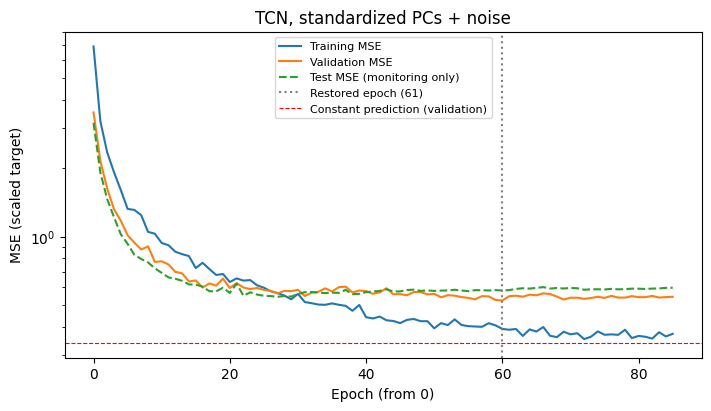

In [25]:
rows = []
for split in ("train", "val", "test"):
    s = result["scores"][split]
    std = targets_phys[split].std()
    rows.append({"set": split, "windows": len(targets_phys[split]), "loss (MSE)": result["final_loss"][split],
                 "R2": s["r2"], "RMSE": s["rmse"], "target std": std, "RMSE / std": s["rmse"] / std})
display(pd.DataFrame(rows).set_index("set").round(6))
print(f"RMSE and target std in {target_unit}; restored epoch {result['best_epoch']} of {result['epochs_run']}")

baseline_val = float(np.mean((y_val - y_train.mean()) ** 2))

fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
ax.plot(result["history"]["loss"], label="Training MSE")
ax.plot(result["history"]["val_loss"], label="Validation MSE")
ax.plot(result["history"]["test_loss"], label="Test MSE (monitoring only)", ls="--")
ax.axvline(result["best_epoch"] - 1, color="gray", ls=":", label=f"Restored epoch ({result['best_epoch']})")
ax.axhline(baseline_val, color="red", ls="--", lw=0.8, label="Constant prediction (validation)")
ax.set(xlabel="Epoch (from 0)", ylabel="MSE (scaled target)" if SCALE_TARGET else "MSE (MPa²)",
       yscale="log", title=result["name"])
ax.legend(fontsize=8)
plt.show()


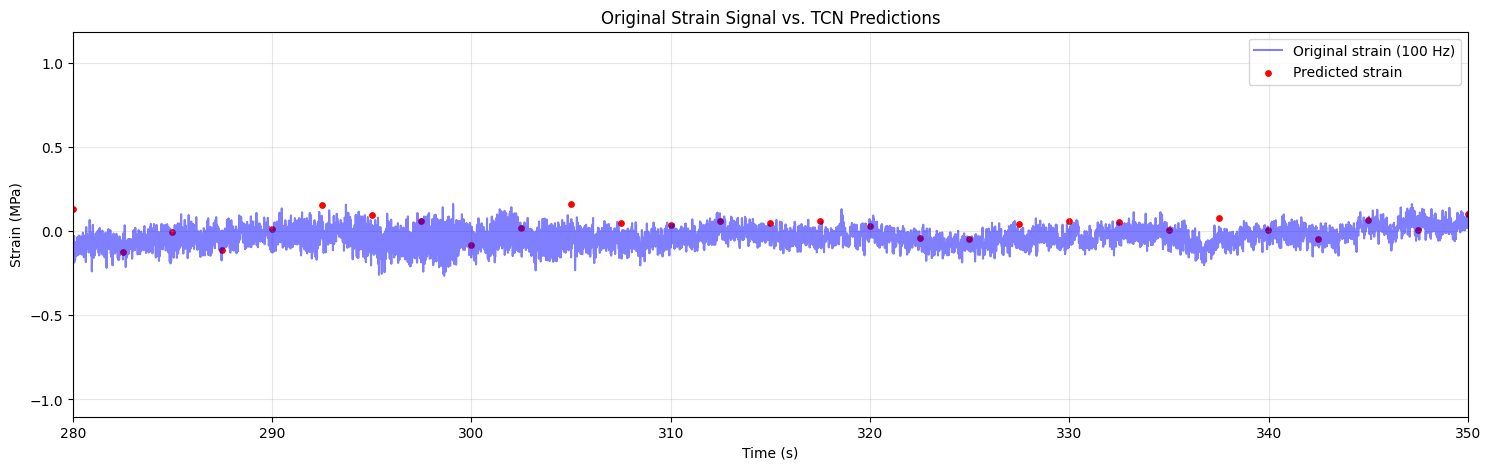

In [26]:
test_recording = recordings[test_names[0]]

plt.figure(figsize=(18, 5))

plt.plot(
    test_recording.index,
    test_recording[TARGET],
    label="Original strain (100 Hz)",
    color="blue",
    alpha=0.5
)

plt.scatter(
    t_test,
    result["predictions"]["test"],
    label="Predicted strain",
    color="red",
    s=15
)

plt.xlim(280, 350)
plt.xlabel("Time (s)")
plt.ylabel("Strain (MPa)")
plt.title("Original Strain Signal vs. TCN Predictions")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [27]:
#testing for one stride
TEST_STRIDE = 1
test_name = test_names[0]

X_test_dense, y_test_dense, t_test_dense = make_windows(
    reduced_full[test_name],
    LONG_WIN,
    TEST_STRIDE
)

### predict using the already trained model for one stride

In [28]:
pred_dense_scaled = result["model"].predict(
    X_test_dense,
    batch_size=32,
    verbose=1
).ravel()

pred_dense = to_physical(pred_dense_scaled)

  13/1939 ━━━━━━━━━━━━━━━━━━━━ 26s 14ms/step

1939/1939 ━━━━━━━━━━━━━━━━━━━━ 27s 14ms/step


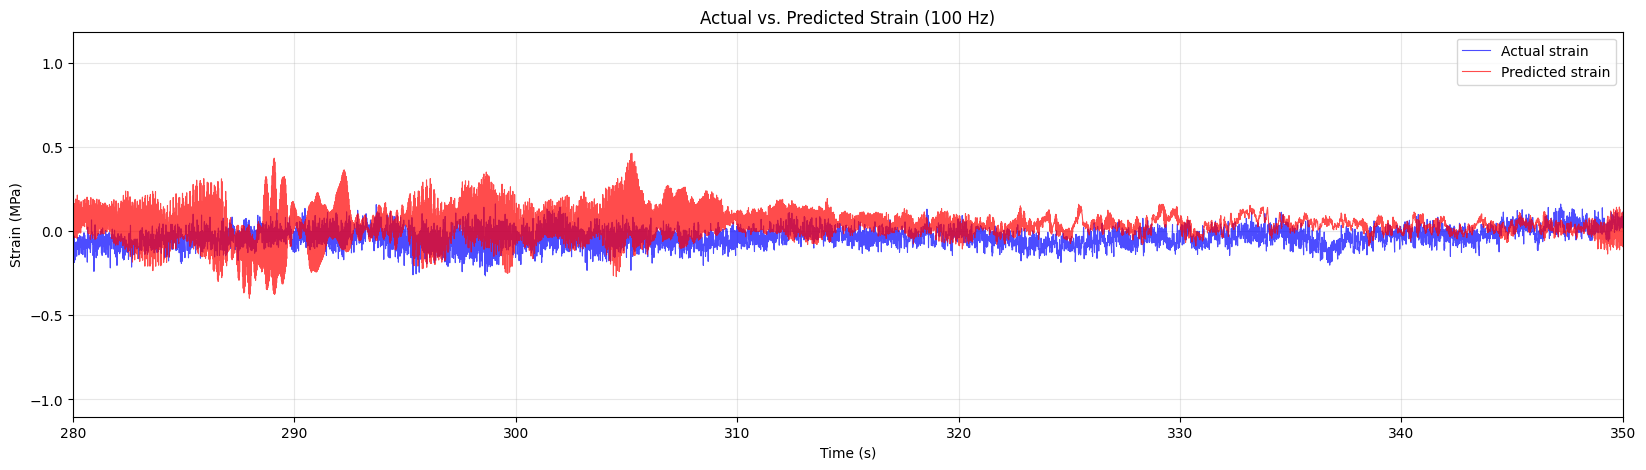

In [29]:
#plotting both predicted and real strain
plt.figure(figsize=(20, 5))

plt.plot(t_test_dense, y_test_dense,
         label="Actual strain", color="blue",
         linewidth=0.8, alpha=0.7)

plt.plot(t_test_dense, pred_dense,
         label="Predicted strain", color="red",
         linewidth=0.8, alpha=0.7)

plt.xlabel("Time (s)")
plt.ylabel(f"Strain ({target_unit})")
plt.title("Actual vs. Predicted Strain (100 Hz)")
plt.legend()
plt.grid(alpha=0.3)
plt.xlim(280, 350)
plt.show()

## Trying 1D CNN + Transformers